In [9]:
import polars as pl
from datetime import date
import yaml
import json
import matplotlib.pyplot as plt
from pathlib import Path
import matplotlib.dates as mdates
import seaborn as sns
import numpy as np
from common import daterange, read_day


with open("../config.yaml", "r") as fp:
    config = yaml.safe_load(fp)

with open("plotting_config.yaml", "r") as fp:
    plotting_config = yaml.safe_load(fp)

Path(f"../output/{config['city']}/descriptives").mkdir(parents=True, exist_ok=True)

In [10]:
def counts_to_dataframe(counts: dict[str, dict[str, int]]) -> pl.DataFrame:
    records = []
    for k, v in counts.items():
        records.append(
            [
                date(*map(int, k.split("-"))),
                v["number_of_records"],
                v["number_of_unique_devices"],
            ]
        )
    return pl.from_records(
        records,
        schema=["day", "number_of_records", "number_of_unique_devices"],
        orient="row",
    )

In [11]:
with open(f"../output/{config['city']}/descriptives/counts_2025.json", "r") as fp:
    counts_2025 = json.load(fp)

In [12]:
cdf_25 = counts_to_dataframe(counts_2025)

In [13]:
oct2025 = cdf_25.filter(
    (pl.col("day") >= date(2025, 10, 1)) & (pl.col("day") <= date(2025, 10, 31))
)
oct2025.head(3)

day,number_of_records,number_of_unique_devices
date,i64,i64
2025-10-01,5270255,74435
2025-10-02,4865105,80256
2025-10-03,5009772,79288


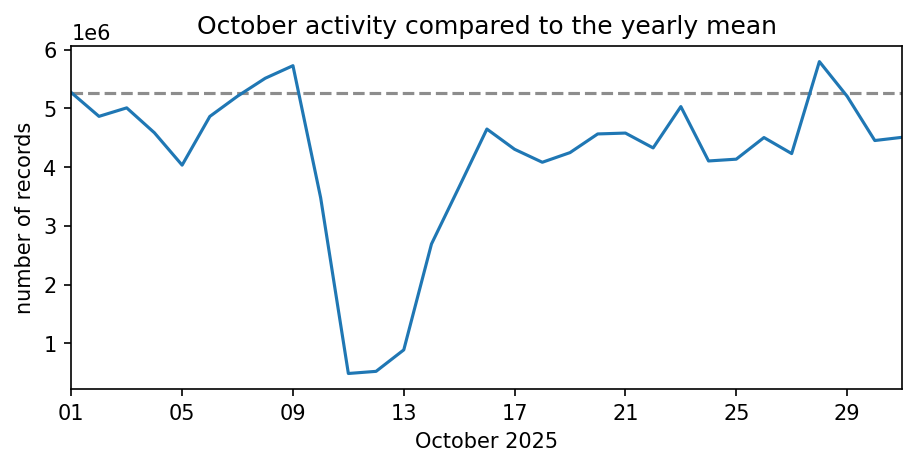

In [14]:
fig, ax = plt.subplots(figsize=(6, 3), dpi=150, layout="constrained")
sns.lineplot(
    # data = oct2025.unpivot(cs.numeric(), index="day"),
    data=oct2025,
    x="day",
    y="number_of_records",
    ax=ax,
)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d"))
ax.set_xlabel("October 2025")
ax.set_ylabel("number of records")
ax.axhline(
    round(np.mean([v["number_of_records"] for k, v in counts_2025.items()])),
    linestyle="dashed",
    color="#8d8d8d",
    zorder=-1,
)
ax.set_title("October activity compared to the yearly mean")
_ = ax.set_xlim([date(2025, 10, 1), date(2025, 10, 31)])


for i in ["png", "svg"]:
    fig.savefig(
        f"../output/{config['city']}/descriptives/october_activity.{i}",
        metadata=plotting_config["metadata"][i],
    )

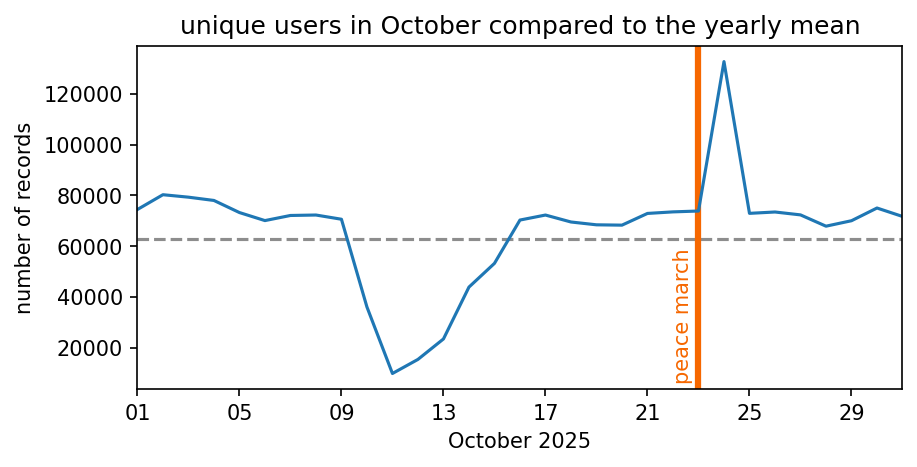

In [15]:
fig, ax = plt.subplots(figsize=(6, 3), dpi=150, layout="constrained")
sns.lineplot(
    data=oct2025,
    x="day",
    y="number_of_unique_devices",
    ax=ax,
)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d"))
ax.set_xlabel("October 2025")
ax.set_ylabel("number of records")
ax.axhline(
    round(np.mean([v["number_of_unique_devices"] for k, v in counts_2025.items()])),
    linestyle="dashed",
    color="#8d8d8d",
    zorder=-1,
)
ax.axvline(
    date(2025, 10, 23),
    linestyle="solid",
    lw=3,
    color="#f66700",
    zorder=1,
)
ax.text(
    date(2025, 10, 22),
    7500,
    "peace march",
    color="#f66700",
    rotation=90,
    zorder=1,
)
ax.set_title("unique users in October compared to the yearly mean")
_ = ax.set_xlim([date(2025, 10, 1), date(2025, 10, 31)])


for i in ["png", "svg"]:
    fig.savefig(
        f"../output/{config['city']}/descriptives/october_unique_users.{i}",
        metadata=plotting_config["metadata"][i],
    )

In [17]:
long_weekend = pl.DataFrame()
for i in daterange(date(2025, 10, 22), date(2025, 10, 26)):
    long_weekend = pl.concat([long_weekend, read_day(i, config["dirs"]["raw_source"])])

In [18]:
long_weekend = long_weekend.sort(["device_aid_hashed", "timestamp"]).unique(
    subset=["device_aid_hashed"], keep="first"
)
long_weekend = long_weekend.with_columns(
    pl.from_epoch(pl.col("timestamp"), time_unit="s")
)

In [19]:
long_weekend.with_columns(
    timestamp=pl.col("timestamp").dt.convert_time_zone(time_zone="Europe/Budapest"),
)

timestamp,device_aid_hashed,device_aid_type,latitude,longitude,horizontal_accuracy,altitude,altitude_accuracy,location_method,ip,OS,OS_version,manufacturer,model,carrier
"datetime[μs, Europe/Budapest]",str,str,f64,f64,f64,f64,f64,str,str,str,str,str,str,str
2025-10-24 13:03:01 CEST,"""000052a8dbca773ddf5257da94247d…","""AAID""",47.347898,19.023785,6.3,0.0,0.0,"""gps""",null,"""Android""","""5.1.1""","""SAMSUNG""",null,null
2025-10-24 13:02:49 CEST,"""0001595ad1bb498576f1d20e1c0ffd…","""AAID""",47.325518,19.151928,20.0,0.0,0.0,"""gps""",null,"""Android""","""15""","""HONOR""","""BRP-NX1M""",null
2025-10-25 02:54:38 CEST,"""00016b388656b3765fa34646840ec5…","""AAID""",47.16,20.22,72.5,0.0,0.0,"""fused""","""217.65.127.255""","""Android""","""15""","""Xiaomi""","""2312DRAABG""",null
2025-10-22 06:19:37 CEST,"""0001852c12c7af746be15a824beddf…","""AAID""",47.429347,19.17194,12.8,163.4,0.0,"""fused""","""84.0.100.198""","""Android""","""11""","""SAMSUNG""",null,null
2025-10-22 05:40:08 CEST,"""00020c77023a159d540c8fe0983561…","""AAID""",47.595121,18.946084,10.0,163.7,0.0,"""gps""",null,"""Android""",null,"""Samsung""","""sm-g975f""",null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2025-10-26 14:52:26 CET,"""fffe5c2ec1659e4a9be547042b8764…","""AAID""",47.50375,19.061096,16.3,149.7,0.0,"""fused""","""176.77.138.172""","""Android""","""15""","""Motorola""","""moto g84 5G""",null
2025-10-22 05:16:44 CEST,"""fffecc750c31524dc2b665dcbe0396…","""AAID""",47.575934,18.404,14.1,0.0,0.0,"""gps""",null,"""Android""","""14""","""Samsung""","""SM-X516B""",null
2025-10-22 07:02:54 CEST,"""fffedcc8f1cd7ad214d0482c3c5df0…","""AAID""",47.562485,19.108635,4.3,115.0,0.0,"""gps""",null,"""Android""","""8.1.1""","""VODAFONE""",null,null


In [20]:
len(
    long_weekend.filter(pl.col("timestamp").dt.strftime("%Y-%m-%d") == "2025-10-23")[
        "device_aid_hashed"
    ].unique()
)

16310

In [21]:
len(
    long_weekend.filter(pl.col("timestamp").dt.strftime("%Y-%m-%d") == "2025-10-24")[
        "device_aid_hashed"
    ].unique()
)

72208

In [22]:
len(
    long_weekend.filter(pl.col("timestamp").dt.strftime("%Y-%m-%d") == "2025-10-25")[
        "device_aid_hashed"
    ].unique()
)

16461

In [23]:
len(
    long_weekend.filter(pl.col("timestamp").dt.strftime("%Y-%m-%d") == "2025-10-26")[
        "device_aid_hashed"
    ].unique()
)

11895

In [24]:
by_hour = (
    long_weekend.with_columns(
        #     timestamp=pl.col("timestamp").dt.convert_time_zone(time_zone="Europe/Budapest"),
        # )
        # .with_columns(
        pl.col("timestamp").dt.strftime("%d").str.to_integer().alias("day"),
        pl.col("timestamp").dt.strftime("%H").str.to_integer().alias("hour"),
    )
    .group_by(["day", "hour"])
    .agg(pl.col("device_aid_hashed").count())
    .sort(["day", "hour"])
)

In [25]:
by_hour

day,hour,device_aid_hashed
i64,i64,u32
22,0,27301
22,1,7161
22,2,2534
22,3,9079
22,4,5397
…,…,…
26,19,240
26,20,179
26,21,102


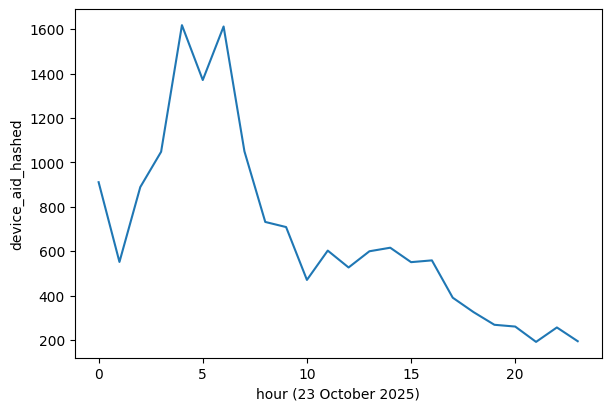

In [26]:
fig, ax = plt.subplots(layout="constrained", figsize=(6, 4))
sns.lineplot(
    data=by_hour.filter(pl.col("day") == 23), x="hour", y="device_aid_hashed", ax=ax
)
ax.set_xlabel("hour (23 October 2025)")
fig.savefig(
    f"../output/{config['city']}/descriptives/oct_23.png",
    metadata=plotting_config["metadata"]["png"],
)

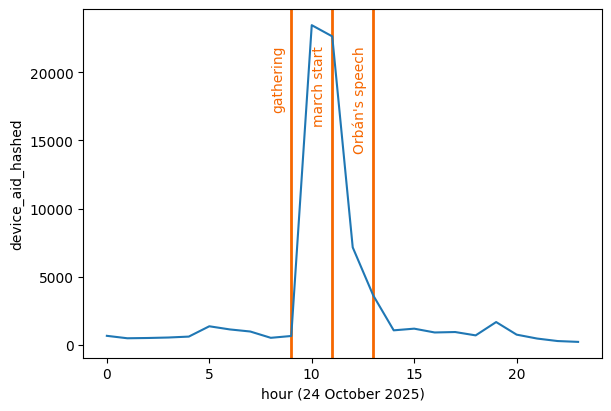

In [27]:
fig, ax = plt.subplots(layout="constrained", figsize=(6, 4))
sns.lineplot(
    data=by_hour.filter(pl.col("day") == 24),
    x="hour",
    y="device_aid_hashed",
    ax=ax,
)
ax.set_xlabel("hour (24 October 2025)")
ax.axvline(9, linestyle="solid", lw=2, color="#f66700", zorder=1)
ax.text(8, 22000, "gathering", color="#f66700", rotation=90, zorder=1, va="top")
ax.axvline(11, linestyle="solid", lw=2, color="#f66700", zorder=1)
ax.text(10, 22000, "march start", color="#f66700", rotation=90, zorder=1, va="top")
ax.axvline(13, linestyle="solid", lw=2, color="#f66700", zorder=1)
ax.text(12, 22000, "Orbán's speech", color="#f66700", rotation=90, zorder=1, va="top")
fig.savefig(
    f"../output/{config['city']}/descriptives/oct_24.png",
    metadata=plotting_config["metadata"]["png"],
)

In [28]:
records = []
for k, v in counts_2025.items():
    if k >= "2025-09-01" and k <= "2025-09-30":
        records.append([k, v["number_of_records"]])
daily_count_sep = pl.from_records(records, schema=["day", "count"], orient="row")
daily_count_sep = daily_count_sep.with_columns(pl.col("day").str.to_date("%Y-%m-%d"))
daily_count_sep = daily_count_sep.with_columns(
    pl.col("day").dt.strftime("%u").str.to_integer().alias("dow")
)
daily_count_sep = daily_count_sep.with_columns(
    pl.when(pl.col.dow > 5)
    .then(pl.lit("weekend"))
    .otherwise(pl.lit("weekday"))
    .alias("val")
)

/tmp/ipykernel_4179001/1799165942.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  _ = ax.set_xticklabels(tuple(range(1, 31)))


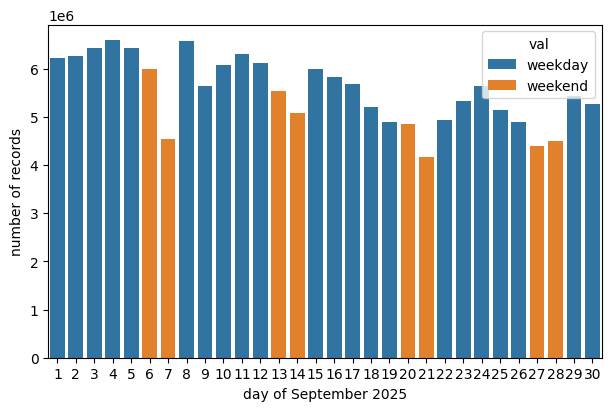

In [29]:
fig, ax = plt.subplots(layout="constrained", figsize=(6, 4))
sns.barplot(
    data=daily_count_sep,
    x="day",
    y="count",
    hue="val",
    ax=ax,
)
ax.set_xlabel("day of September 2025")
ax.set_ylabel("number of records")
_ = ax.set_xticklabels(tuple(range(1, 31)))

In [30]:
records = []
for k, v in counts_2025.items():
    if k >= "2025-10-01" and k <= "2025-10-31":
        records.append([k, v["number_of_records"]])
daily_count_oct = pl.from_records(records, schema=["day", "count"], orient="row")
daily_count_oct = daily_count_oct.with_columns(pl.col("day").str.to_date("%Y-%m-%d"))
daily_count_oct = daily_count_oct.with_columns(
    pl.col("day").dt.strftime("%u").str.to_integer().alias("dow")
)
daily_count_oct = daily_count_oct.with_columns(
    pl.when(pl.col.dow > 5)
    .then(pl.lit("weekend"))
    .otherwise(pl.lit("weekday"))
    .alias("val")
)

/tmp/ipykernel_4179001/559037510.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  _ = ax.set_xticklabels(tuple(range(1, 31)))


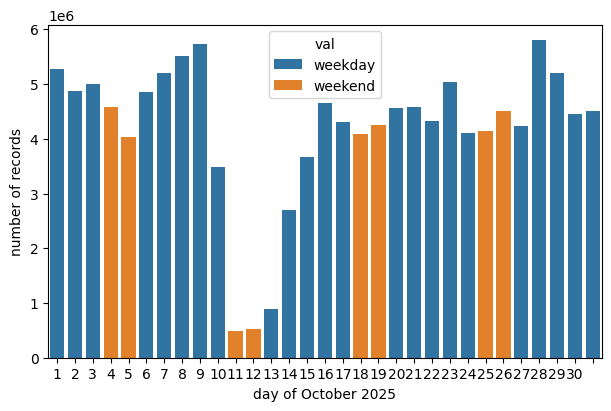

In [31]:
fig, ax = plt.subplots(layout="constrained", figsize=(6, 4))
sns.barplot(
    data=daily_count_oct,
    x="day",
    y="count",
    hue="val",
    ax=ax,
)
ax.set_xlabel("day of October 2025")
ax.set_ylabel("number of records")
_ = ax.set_xticklabels(tuple(range(1, 31)))

In [32]:
records = []
for k, v in counts_2025.items():
    if k >= "2025-11-01" and k <= "2025-11-30":
        records.append([k, v["number_of_records"]])
daily_count_nov = pl.from_records(records, schema=["day", "count"], orient="row")
daily_count_nov = daily_count_nov.with_columns(pl.col("day").str.to_date("%Y-%m-%d"))
daily_count_nov = daily_count_nov.with_columns(
    pl.col("day").dt.strftime("%u").str.to_integer().alias("dow")
)
daily_count_nov = daily_count_nov.with_columns(
    pl.when(pl.col.dow > 5)
    .then(pl.lit("weekend"))
    .otherwise(pl.lit("weekday"))
    .alias("val")
)

/tmp/ipykernel_4179001/144121987.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  _ = ax.set_xticklabels(tuple(range(1, 31)))


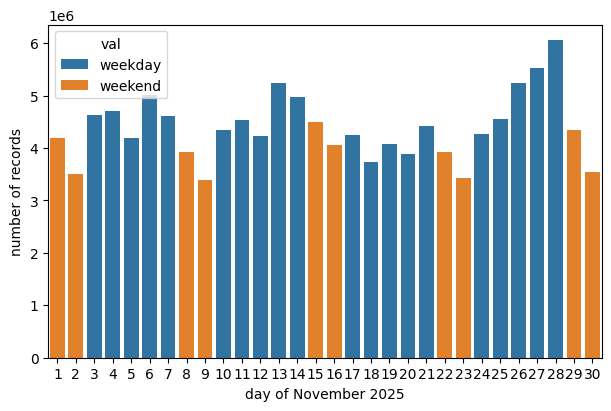

In [33]:
fig, ax = plt.subplots(layout="constrained", figsize=(6, 4))
sns.barplot(
    data=daily_count_nov,
    x="day",
    y="count",
    hue="val",
    ax=ax,
    hue_order=["weekday", "weekend"],
)
ax.set_xlabel("day of November 2025")
ax.set_ylabel("number of records")
_ = ax.set_xticklabels(tuple(range(1, 31)))

In [34]:
records = []
for k, v in counts_2025.items():
    if k >= "2025-12-01":
        records.append([k, v["number_of_records"]])
daily_count_dec = pl.from_records(records, schema=["day", "count"], orient="row")
daily_count_dec = daily_count_dec.with_columns(pl.col("day").str.to_date("%Y-%m-%d"))
daily_count_dec = daily_count_dec.with_columns(
    pl.col("day").dt.strftime("%u").str.to_integer().alias("dow")
)
daily_count_dec = daily_count_dec.with_columns(
    pl.when(pl.col.dow > 5)
    .then(pl.lit("weekend"))
    .otherwise(pl.lit("weekday"))
    .alias("val")
)
daily_count_dec = daily_count_dec.with_columns(
    pl.when(pl.col.day.is_in([date(2025, 12, 25), date(2025, 12, 26)]))
    .then(pl.lit("weekend"))
    .otherwise(pl.col.val)
    .alias("val")
)

/tmp/ipykernel_4179001/1923543149.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  _ = ax.set_xticklabels(tuple(range(1, 32)))


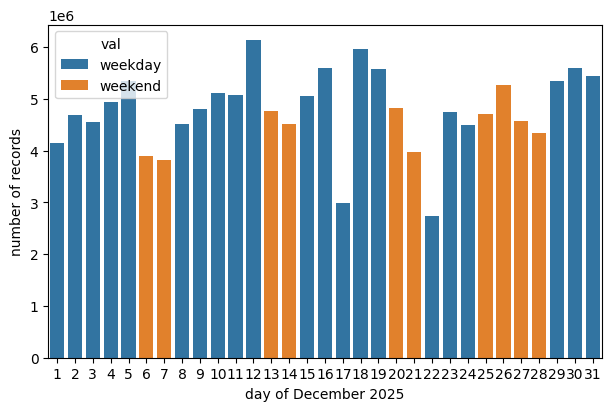

In [35]:
fig, ax = plt.subplots(layout="constrained", figsize=(6, 4))
sns.barplot(
    data=daily_count_dec,
    x="day",
    y="count",
    hue="val",
    ax=ax,
)
ax.set_xlabel("day of December 2025")
ax.set_ylabel("number of records")
_ = ax.set_xticklabels(tuple(range(1, 32)))